In [1]:
from sklearn.datasets import make_regression
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression


In [2]:
X,y = make_regression(n_samples=4, n_features=1, n_informative=1, n_targets=1,noise=80,random_state=13)

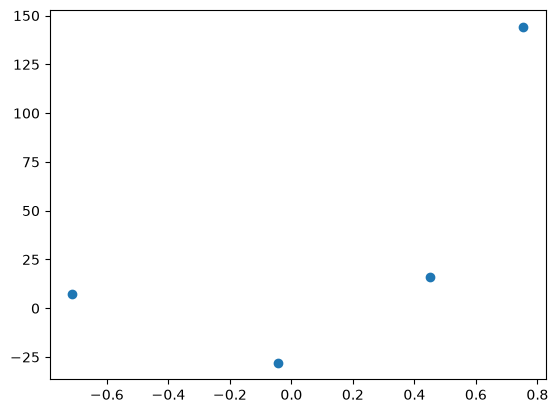

In [3]:
plt.scatter(X,y)

In [4]:
# applying OLS 

model = LinearRegression()

In [5]:
model.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[78.35]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,26.16
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[1.11]


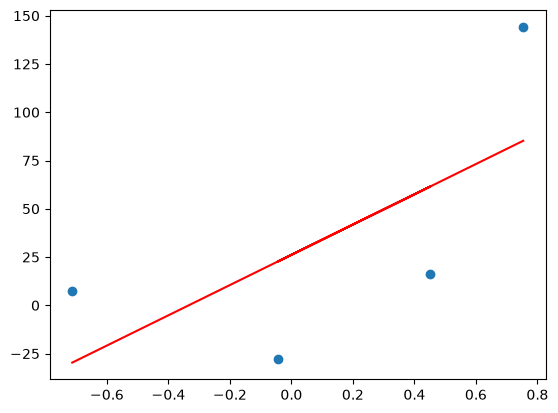

In [6]:
plt.scatter(X,y)
plt.plot(X,model.predict(X),color='red')

In [7]:
model.coef_

array([78.35063668])

In [8]:
model.intercept_

np.float64(26.15963284313262)

In [9]:
#step1 : applying GD assuming 
#  m = 78.35063668 and b = 0

y_pred = ((78.35063668 * X) + 100).reshape(4)


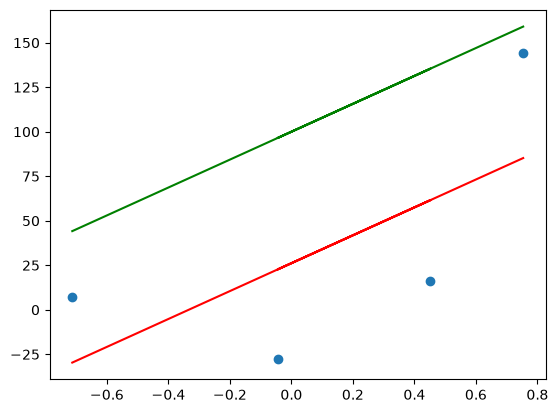

In [10]:
plt.scatter(X,y)
plt.plot(X,model.predict(X),color='red')
plt.plot(X,y_pred,color='green')

In [11]:
m = 78.35063668
b = 100

loss_slope = -2*np.sum(y-(m*X.ravel()) - b)
loss_slope

np.float64(590.7229372554102)

In [12]:
lr = 0.1

step_size = lr * loss_slope
step_size

np.float64(59.07229372554102)

In [13]:
b = b - step_size
b

np.float64(40.92770627445898)

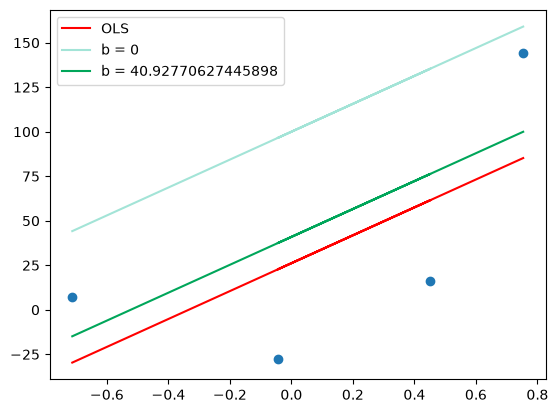

In [14]:
y_pred1 = ((m*X) + b).reshape(4)

plt.scatter(X,y)
plt.plot(X,model.predict(X),color='red',label='OLS')
plt.plot(X,y_pred,color='#A3E4D7',label='b = 0')
plt.plot(X,y_pred1,color='#00a65a',label='b = {}'.format(b))
plt.legend()


In [15]:
#Iteration1 

loss_slope = -2*np.sum(y-(m*X.ravel()) - b)
loss_slope

np.float64(118.14458745108196)

In [16]:
step_size = lr*loss_slope
step_size


np.float64(11.814458745108197)

In [17]:
b = b - step_size
b

np.float64(29.11324752935078)

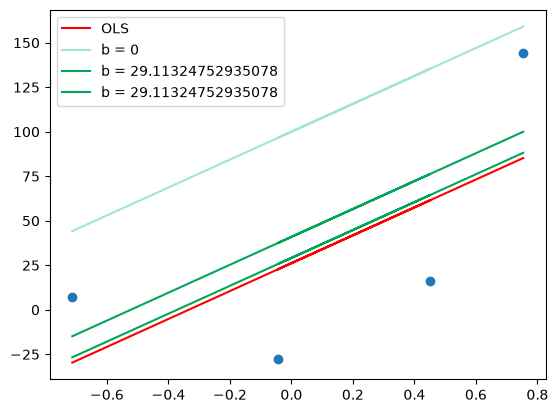

In [18]:
y_pred2 = (m*X + b).reshape(4)

plt.scatter(X,y)
plt.plot(X,model.predict(X),color='red',label='OLS')
plt.plot(X,y_pred,color='#A3E4D7',label='b = 0')
plt.plot(X,y_pred1,color='#00a65a',label='b = {}'.format(b))
plt.plot(X,y_pred2,color='#00a65a',label='b = {}'.format(b))
plt.legend()


In [19]:
# Iteration 3
loss_slope = -2 * np.sum(y - m*X.ravel() - b)
loss_slope

np.float64(23.62891749021638)

In [20]:
step_size = loss_slope*lr
step_size

np.float64(2.3628917490216383)

In [21]:
b = b - step_size
b

np.float64(26.75035578032914)

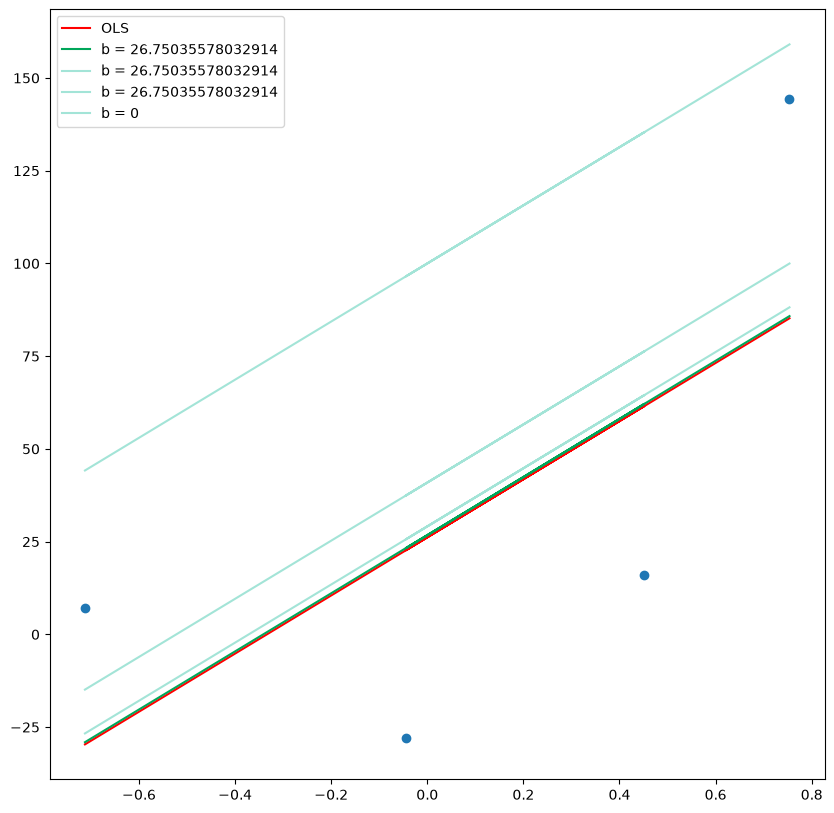

In [22]:
y_pred3 = ((78.35 * X) + b).reshape(4)

plt.figure(figsize=(10,10))
plt.scatter(X,y)
plt.plot(X,model.predict(X),color='red',label='OLS')
plt.plot(X,y_pred3,color='#00a65a',label='b = {}'.format(b))
plt.plot(X,y_pred2,color='#A3E4D7',label='b = {}'.format(b))
plt.plot(X,y_pred1,color='#A3E4D7',label='b = {}'.format(b))
plt.plot(X,y_pred,color='#A3E4D7',label='b = 0')
plt.legend()
plt.show()

In [23]:
# so at this point 
# b - b(actual) 
# 
26.07208771615711 - model.intercept_ 

np.float64(-0.08754512697550965)

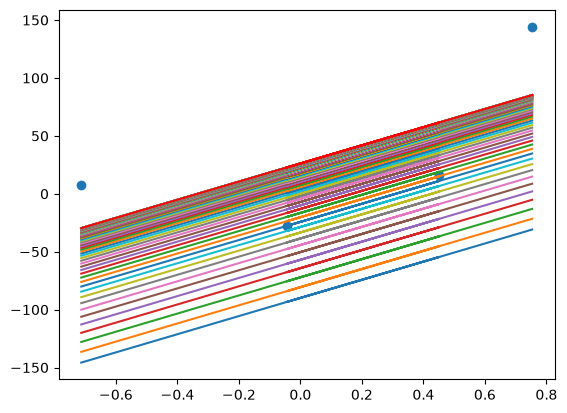

In [24]:
m = 78.35063668
b =-100

lr = 0.01
epochs = 100

for i in range(epochs):
    loss_slope = -2*np.sum(y - (m*X.ravel()) - b)
    
    b = b - (lr*loss_slope)

    y_pred=m*X+b
    plt.plot(X,y_pred)

plt.scatter(X,y)   
plt.plot(X,model.predict(X),color='red')